In [2]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_inverse(y): 
    return np.log(y / (1 - y))  # Inverse sigmoid for better weight initialization

# Input Data (5 samples, each 3 fetuere)
X = np.array([[1, 0, 1],
              [0, 1, 0],
              [1, 1, 1],
              [0, 0, 1],
              [1, 0, 0]]).T  # Transposed to match matrix dimensions

print("Input: ")
print(X.T)

Input: 
[[1 0 1]
 [0 1 0]
 [1 1 1]
 [0 0 1]
 [1 0 0]]


In [4]:
# Adjust Encoder weights to reduce dimensions into 2
W_enc = np.array([[5, -5, 5],
                 [-5, 5, -5]])  # 2D latent space

# Encoding Step
Z_enc = np.dot(W_enc, X)
A_enc = sigmoid(Z_enc)

print("\nEncoded Representation (2D): ")
print(A_enc.T)


Encoded Representation (2D): 
[[9.99954602e-01 4.53978687e-05]
 [6.69285092e-03 9.93307149e-01]
 [9.93307149e-01 6.69285092e-03]
 [9.93307149e-01 6.69285092e-03]
 [9.93307149e-01 6.69285092e-03]]


In [8]:
# Adjusted Weights to map back to 3 dimensions
W_dec = np.array([[5, -5],
                  [-5, 5],
                  [5, -5]])

# dECODING STEP
Z_dec = np.dot(W_dec, A_enc)
A_dec = sigmoid(Z_dec)

print("\nReconstructed Output: ")
print(A_enc.T)



Reconstructed Output: 
[[9.99954602e-01 4.53978687e-05]
 [6.69285092e-03 9.93307149e-01]
 [9.93307149e-01 6.69285092e-03]
 [9.93307149e-01 6.69285092e-03]
 [9.93307149e-01 6.69285092e-03]]


In [9]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_inverse(y): 
    return np.log(y / (1 - y))  # Inverse sigmoid for better weight initialization

# Input Data (5 samples, each 3 fetuere)
X = np.array([[1, 0, 1],
              [0, 1, 0],
              [1, 1, 1],
              [0, 0, 1],
              [1, 0, 0]]).T  # Transposed to match matrix dimensions

print("Input: ")
print(X.T)

# Adjust Encoder weights to reduce dimensions into 2
W_enc = np.array([[5, -5, 5],
                 [-5, 5, -5]])  # 2D latent space

# Encoding Step
Z_enc = np.dot(W_enc, X)
A_enc = sigmoid(Z_enc)

print("\nEncoded Representation (2D): ")
print(A_enc.T)

# Adjusted Weights to map back to 3 dimensions
W_dec = np.array([[5, -5],
                  [-5, 5],
                  [5, -5]])

# dECODING STEP
Z_dec = np.dot(W_dec, A_enc)
A_dec = sigmoid(Z_dec)

print("\nReconstructed Output: ")
print(A_enc.T)


Input: 
[[1 0 1]
 [0 1 0]
 [1 1 1]
 [0 0 1]
 [1 0 0]]

Encoded Representation (2D): 
[[9.99954602e-01 4.53978687e-05]
 [6.69285092e-03 9.93307149e-01]
 [9.93307149e-01 6.69285092e-03]
 [9.93307149e-01 6.69285092e-03]
 [9.93307149e-01 6.69285092e-03]]

Reconstructed Output: 
[[9.99954602e-01 4.53978687e-05]
 [6.69285092e-03 9.93307149e-01]
 [9.93307149e-01 6.69285092e-03]
 [9.93307149e-01 6.69285092e-03]
 [9.93307149e-01 6.69285092e-03]]


In [4]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# --- 1. Load DAta
# csv_file = "F:/Users/MSR/Documents/CST4200/15/Datasets/clusters.csv"
csv_file = "F:/Users/MSR/Documents/CST4200/15/Datasets/Wholesale customers data.csv"

# --- 2.Read Data from CSV File
df0 = pd.read_csv(csv_file)
# =======================================================================================


# df = pd.read_csv("wholesale.csv")
df = pd.read_csv(csv_file)

# 1. Keep only continuous spend columns
spend_cols = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
X_raw = df[spend_cols].values.astype(np.float32)

# 2. log1p to tame the heavy right tail
X_log = np.log1p(X_raw)

# 3. Standardize to zero mean / unit variance
scaler = StandardScaler()
X = scaler.fit_transform(X_log).astype(np.float32)   # shape (440, 6)

# Keep Channel/Region aside in case you want them later
meta = df[['Channel','Region']].copy()

print(X.shape, X.mean(0).round(3), X.std(0).round(3))

(440, 6) [-0. -0.  0. -0.  0. -0.] [1. 1. 1. 1. 1. 1.]


In [5]:
import torch
import torch.nn as nn

torch.manual_seed(0)

class Autoencoder(nn.Module):
    def __init__(self, n_in=6, n_latent=2, hidden=4):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_in, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_latent),
        )
        self.decoder = nn.Sequential(
            nn.Linear(n_latent, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_in),      # linear output — we reconstruct standardized values
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

model = Autoencoder(n_in=6, n_latent=2, hidden=4)
print(model)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=6, out_features=4, bias=True)
    (1): ReLU()
    (2): Linear(in_features=4, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=4, bias=True)
    (1): ReLU()
    (2): Linear(in_features=4, out_features=6, bias=True)
  )
)


In [6]:
from torch.utils.data import TensorDataset, DataLoader

X_t = torch.from_numpy(X)
loader = DataLoader(TensorDataset(X_t, X_t), batch_size=32, shuffle=True)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(200):
    epoch_loss = 0.0
    for xb, yb in loader:
        optimizer.zero_grad()
        x_hat, _ = model(xb)
        loss = loss_fn(x_hat, yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(xb)
    epoch_loss /= len(X_t)
    if epoch % 20 == 0:
        print(f"epoch {epoch:3d}  MSE {epoch_loss:.4f}")

epoch   0  MSE 1.2026
epoch  20  MSE 0.8102
epoch  40  MSE 0.4402
epoch  60  MSE 0.3498
epoch  80  MSE 0.3124
epoch 100  MSE 0.2979
epoch 120  MSE 0.2895
epoch 140  MSE 0.2842
epoch 160  MSE 0.2808
epoch 180  MSE 0.2789


In [7]:
model.eval()
with torch.no_grad():
    X_hat, Z = model(X_t)
    X_hat = X_hat.numpy()
    Z = Z.numpy()

# MSE in standardized space
mse = np.mean((X_hat - X) ** 2)
print("Reconstruction MSE (standardized):", mse)

# Back to original spend units for interpretability
X_hat_log = scaler.inverse_transform(X_hat)
X_hat_orig = np.expm1(X_hat_log)      # inverse of log1p
X_orig = np.expm1(scaler.inverse_transform(X))

# Per-feature relative error
for i, c in enumerate(spend_cols):
    mae = np.mean(np.abs(X_hat_orig[:, i] - X_orig[:, i]))
    rel = mae / np.mean(X_orig[:, i])
    print(f"{c:18s} MAE={mae:8.1f}  rel={rel:.2%}")

Reconstruction MSE (standardized): 0.27629104
Fresh              MAE=  6408.8  rel=53.40%
Milk               MAE=  1858.9  rel=32.07%
Grocery            MAE=  2189.8  rel=27.54%
Frozen             MAE=  1520.4  rel=49.49%
Detergents_Paper   MAE=  1156.2  rel=40.13%
Delicassen         MAE=   714.0  rel=46.82%


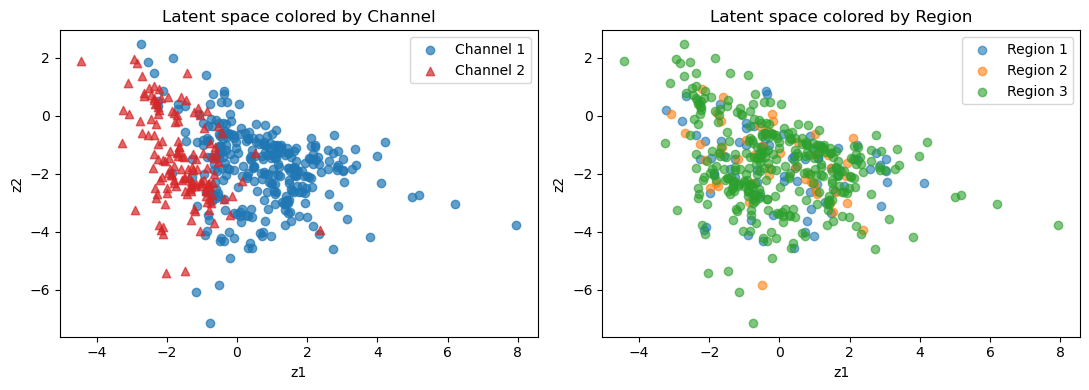

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# colored by Channel
for ch, marker in [(1, 'o'), (2, '^')]:
    m = meta['Channel'].values == ch
    axes[0].scatter(Z[m, 0], Z[m, 1], c=('tab:blue' if ch == 1 else 'tab:red'),
                    marker=marker, label=f"Channel {ch}", alpha=0.7)
axes[0].set_title("Latent space colored by Channel")
axes[0].legend(); axes[0].set_xlabel("z1"); axes[0].set_ylabel("z2")

# colored by Region
for rg in sorted(meta['Region'].unique()):
    m = meta['Region'].values == rg
    axes[1].scatter(Z[m, 0], Z[m, 1], label=f"Region {rg}", alpha=0.6)
axes[1].set_title("Latent space colored by Region")
axes[1].legend(); axes[1].set_xlabel("z1"); axes[1].set_ylabel("z2")

plt.tight_layout(); plt.show()

In [9]:
np.random.seed(0)

n_in, n_h, n_z = 6, 8, 2
W1 = np.random.randn(n_h, n_in) * 0.1
b1 = np.zeros((n_h, 1))
W2 = np.random.randn(n_z, n_h) * 0.1
b2 = np.zeros((n_z, 1))
W3 = np.random.randn(n_h, n_z) * 0.1
b3 = np.zeros((n_h, 1))
W4 = np.random.randn(n_in, n_h) * 0.1
b4 = np.zeros((n_in, 1))

relu  = lambda x: np.maximum(0, x)
drelu = lambda x: (x > 0).astype(x.dtype)

Xt = X.T.copy()          # (6, 440), samples as columns
lr = 1e-3

for epoch in range(3000):
    # forward
    z1 = W1 @ Xt + b1; a1 = relu(z1)
    z2 = W2 @ a1 + b2; a2 = z2                    # latent, linear
    z3 = W3 @ a2 + b3; a3 = relu(z3)
    z4 = W4 @ a3 + b4; out = z4                   # linear output
    err = out - Xt
    loss = np.mean(err ** 2)
    # backward
    d4 = 2 * err / err.size
    dW4 = d4 @ a3.T; db4 = d4.sum(1, keepdims=True)
    d3 = (W4.T @ d4) * drelu(z3)
    dW3 = d3 @ a2.T; db3 = d3.sum(1, keepdims=True)
    d2 = W3.T @ d3                                # latent is linear
    dW2 = d2 @ a1.T; db2 = d2.sum(1, keepdims=True)
    d1 = (W2.T @ d2) * drelu(z1)
    dW1 = d1 @ Xt.T; db1 = d1.sum(1, keepdims=True)
    # update
    for p, g in [(W1,dW1),(b1,db1),(W2,dW2),(b2,db2),
                 (W3,dW3),(b3,db3),(W4,dW4),(b4,db4)]:
        p -= lr * g
    if epoch % 300 == 0:
        print(epoch, f"loss={loss:.4f}")

0 loss=0.9995
300 loss=0.9991
600 loss=0.9990
900 loss=0.9989
1200 loss=0.9989
1500 loss=0.9988
1800 loss=0.9988
2100 loss=0.9987
2400 loss=0.9987
2700 loss=0.9986


In [10]:
Implementing an Autoencoder on the Wholesale Customers dataset
This is the classic Wholesale Customers dataset (440 rows, 8 columns). 
    The columns Channel and Region are categorical — you almost certainly do not want to feed them into an autoencoder that compresses the spending features. 
    The interesting signal is the 6 continuous spend columns:

Fresh, Milk, Grocery, Frozen, Detergents_Paper, Delicassen

A few things matter a lot on this dataset before any autoencoder will work:

Drop the categorical columns (Channel, Region) — or one-hot them separately. 
    They aren't continuous spend, and they'll dominate a naive autoencoder.

Features are hugely different in scale — Fresh can be ~0–100k, Delicassen ~0–10k. 
    Standardize (or log-transform + standardize). 
    This is the #1 reason people get garbage autoencoders on this dataset.

Data is right-skewed (many small values, a few very large). 
    log1p then StandardScaler works very well.

A linear (PCA-like) autoencoder with a linear output is often enough on 6 features. 
    A nonlinear one (sigmoid/ReLU) helps only if you feed it normalized data. 
        Sigmoid output on raw spend values is wrong — sigmoid outputs are in (0,1).

Below is a complete, runnable implementation using PyTorch (you can port to NumPy easily — the previous message's NumPy loop is the same math).

    1. Load, clean, transform

Why log1p? Fresh has values in the tens of thousands and a long tail. 
    Without it, the autoencoder will essentially learn "reconstruct Fresh and ignore everything else," because MSE is dominated by the largest-scale feature.

    2. Define the autoencoder (3-layer, bottleneck = 2 or 3)

Key choices and why:

Linear output layer, not sigmoid. 
    You're reconstructing standardized numbers (can be negative, > 1). 
    Sigmoid would clamp them to (0, 1) and destroy the reconstruction. 
        (This is exactly the pitfall in your earlier snippet.)

ReLU hidden, not sigmoid, because inputs are centered (sigmoid saturates for large |x|; the dataset has z-scores up to ±5).

Bottleneck 2 for visualization/clustering (this dataset is famous for having ~2 meaningful components: "retail vs. fresh" and "milk/grocery/detergent vs. frozen"). 
    Use 3 if you want low reconstruction loss.


    3. Training loop

Expected behavior: MSE drops to roughly 0.10–0.25 in standardized units with a 2-D bottleneck 
                    (you can't reach ~0 because 6 → 2 is lossy). 
                    With latent=3 you'll get noticeably lower loss.


    4. Evaluate + recover original units

You will see Fresh, Grocery, Detergents_Paper reconstruct well (they dominate the variance), 
                               while Frozen / Delicassen reconstruct worse — that's information-theoretic, not a bug.


    5. Visualize the latent space

You should see a clean left/right split by Channel in the latent space — Channel was never fed to the model, so this is a genuine emergent cluster. 
            That's the most convincing sanity check for this dataset. 
            (People have used exactly this plot to argue the autoencoder learns useful structure — e.g., "retail vs. wholesale/HoReCa customers.")


    6. Sanity checks & things that go wrong
Symptom	Cause	Fix
Loss plateaus high, 
                reconstruction is a constant	
                Forgot log1p/StandardScaler; 
                huge values dominate	Always scale inputs
Reconstruction ≈ constant 0.5 everywhere	
                Sigmoid output layer with standardized inputs	
                Use a linear output layer
Latent space has zero structure, loss ≈ 0	
                Bottleneck too wide (≥ input dim)	Shrink latent to 2–3
Training loss drops but per-feature MAE is huge	Comparing standardized loss vs raw spend units	
                Use expm1/inverse_transform (step 4)
Channel/Region get reconstructed perfectly and nothing else does	
                You fed the categorical columns in with integer codes	
                Drop them; use one-hot only if you really want them

    7. If you want a pure-NumPy version (no PyTorch)
Same math as your earlier snippet, just fixed:


The changes vs. your original snippet:

±5 weights → small random init (0.1).

No sigmoid output → linear output layer (crucial: you're reconstructing standardized values, not probabilities).

ReLU hidden layers, sensible bottleneck (2–3), biases added.

Actual backprop with a gradient step — not just a forward pass with hand-set weights.

Inputs standardized (plus log1p), not raw 0–100k spend values.

TL;DR for this dataset
Use the 6 spend columns only; drop Channel/Region (use them later for coloring the latent space).

log1p + StandardScaler — this single step is what makes or breaks the autoencoder on this data.

Linear output layer, ReLU hidden, bottleneck 2, Adam, ~200 epochs.

Check the latent scatter against Channel — a clean left/right split means it learned real structure.

Expect the biggest reconstruction errors on Frozen and Delicassen — that's the 6→2 bottleneck doing its job, not a bug.

SyntaxError: invalid character '—' (U+2014) (2005152765.py, line 2)